# 04 · Survival analysis (lifelines)
Duration = `tenure_months`; event = `churn`; active customers are right-censored.

In [1]:
import sys, warnings; sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display, Image
from src import config
pd.set_option('display.width', 160); sns.set_theme(style='whitegrid')
from src import survival_model as sm
df = pd.read_csv(config.DATA_PROCESSED / 'customers_processed.csv')   # cleaned + engineered (written by ingestion)
print('events', df.churn.sum(), 'censored', (1-df.churn).sum())
km = sm.fit_kaplan_meier(df); display(sm.km_summary(km).round(3))
print(sm.logrank_by_group(df, 'contract'))

events 1869 censored 5174


,months,survival_probability
0,6,0.885
1,12,0.843
2,24,0.789
3,36,0.749
4,48,0.709
5,60,0.664
6,72,0.593


{'test_statistic': 2352.8725382593398, 'p_value': 0.0, 'df': 2}


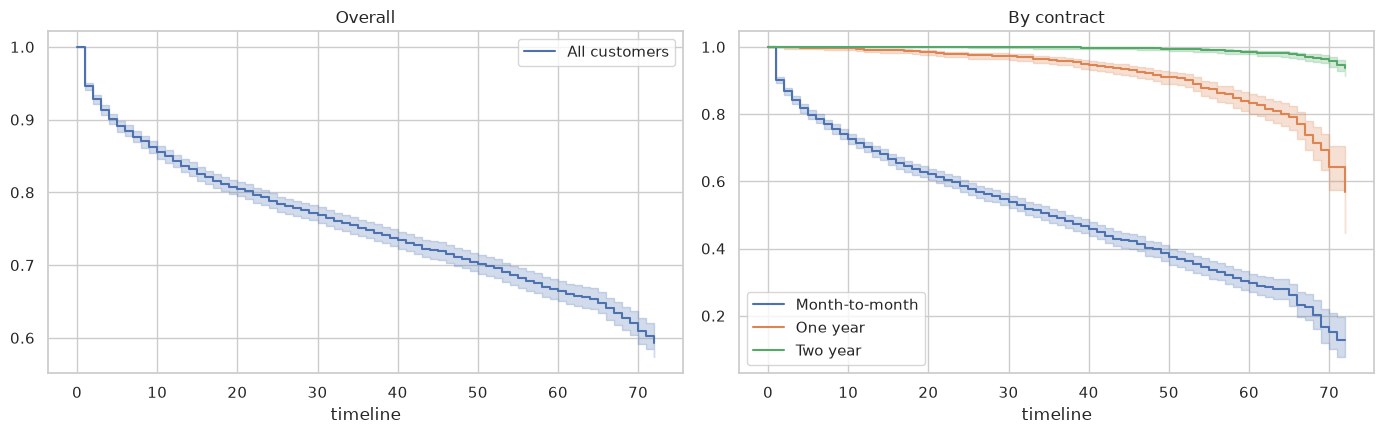

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5)); km.plot_survival_function(ax=ax[0])
for k in sm.km_by_group(df, 'contract').values(): k.plot_survival_function(ax=ax[1])
ax[0].set_title('Overall'); ax[1].set_title('By contract'); plt.tight_layout()

In [3]:
cph_u, d_u = sm.fit_cox(df, stratify_contract=False)
print('concordance', round(cph_u.concordance_index_, 3)); display(sm.hazard_ratios(cph_u).round(3))

concordance 0.869


,covariate,hazard_ratio,hr_lower_95,hr_upper_95,p_value
0,pay_electronic_check,1.732,1.522,1.970,0.000
1,pay_mailed_check,1.668,1.421,1.957,0.000
2,internet_fiber,1.347,1.096,1.656,0.005
3,paperless_billing,1.203,1.080,1.340,0.001
4,monthly_charges_per10usd,1.028,0.963,1.097,0.405
5,phone_service,1.023,0.814,1.285,0.846
6,streaming_tv,0.925,0.818,1.045,0.210
7,senior_citizen,0.894,0.803,0.996,0.042
8,pay_credit_card_auto,0.883,0.750,1.041,0.138
9,streaming_movies,0.834,0.737,0.943,0.004


In [4]:
ph = sm.check_ph_assumption(cph_u, d_u); display(ph.round(4))
print('violations:', ph.loc[ph.violates_ph_at_5pct, 'covariate'].tolist())

,covariate,test_statistic,p,violates_ph_at_5pct
0,contract_one_year,27.9855,0.0000,True
1,contract_two_year,0.0409,0.8397,False
2,dependents,22.2596,0.0000,True
3,device_protection,2.4314,0.1189,False
4,internet_fiber,0.5061,0.4769,False
5,internet_none,0.2374,0.6261,False
6,monthly_charges_per10usd,0.3706,0.5427,False
7,multiple_lines,14.0617,0.0002,True
8,online_backup,6.5169,0.0107,True
9,online_security,10.2095,0.0014,True


violations: ['contract_one_year', 'dependents', 'multiple_lines', 'online_backup', 'online_security', 'partner', 'pay_electronic_check', 'pay_mailed_check', 'streaming_movies', 'streaming_tv', 'tech_support']


Several covariates violate proportional hazards. A Cox model stratified by contract (used for predictions) removes the contract assumption, but other violations remain, so hazard ratios are time-averaged effects.

In [5]:
cph, d = sm.fit_cox(df, stratify_contract=True); print('stratified concordance', round(cph.concordance_index_, 3))
sp = sm.survival_predictions(cph, df); display(sp.describe().round(3))

stratified concordance 0.729


,partial_hazard,surv_prob_12m,surv_prob_24m,surv_prob_36m,expected_months_next_24
count,7043.000,7043.000,7043.000,7043.000,7043.000
mean,1.550,0.810,0.707,0.634,19.601
std,1.431,0.233,0.303,0.338,5.074
min,0.052,0.003,0.001,0.000,1.061
25%,0.472,0.706,0.492,0.332,16.901
50%,1.084,0.905,0.809,0.718,21.553
75%,2.125,0.994,0.982,0.965,23.808
max,6.855,1.000,1.000,1.000,24.000


In [6]:
r = df.sort_values('monthly_charges').tail(1); display(sm.customer_curve(cph, r).set_index('months_from_now').T.iloc[:, ::6].round(3))

months_from_now,0,6,12,18,24,30,36
survival_probability,1.0,1.0,1.0,1.0,1.0,1.0,1.0
